# SS3 Part B: STADIO 1 subscriber churn prediction on the client data extract

**Method applied:** the final method chosen in SS2: a gradient-boosted tree classifier (XGBoost), compared against the logistic-regression baseline and the simple "no recent viewing" rule from the SS1 problem statement.
**Task:** predict which STADIO 1 TV subscribers will cancel (voluntarily, by payment failure or by non-renewal) in the next 30 days, early enough for a retention action to change the outcome.

The notebook has five components, each clearly marked with a heading and committed separately:

| # | Component | Marks |
|---|---|---|
| 1 | Dataset loading | 2 |
| 2 | Dataset preprocessing (incl. train / validation / test split) | 5 |
| 3 | Model training (incl. hyper-parameter justification) | 5 |
| 4 | Model validation (unseen test subset) | 5 |
| 5 | Results visualisation (training and unseen) | 3 |

Run top to bottom. Set `STADIO_DATA_DIR` (or place the CSVs in `data/raw/stadioone/`) if your data lives elsewhere.

---
# 1. DATASET LOADING
*(Component 1 of 5)*

In [1]:
import json, os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
SEED = 42
np.random.seed(SEED)

# Look for the client extract in a few sensible places (first match wins).
CANDIDATES = [os.environ.get("STADIO_DATA_DIR", ""), "data/raw/stadioone", "data/raw", "stadioone",
              "iitaemmanuel_client_data/stadioone", "../data/raw/stadioone"]
DATA_DIR = next((Path(p) for p in CANDIDATES if p and (Path(p) / "table1_subscriptions.csv").exists()), None)
assert DATA_DIR is not None, "Client CSVs not found: set STADIO_DATA_DIR or copy them to data/raw/stadioone/"
OUT_DIR = Path(os.environ.get("STADIO_OUT_DIR", "outputs")); (OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
print("Reading client data from:", DATA_DIR.resolve())

FILES = {"subs": "table1_subscriptions", "pay": "table2_billing_payments", "view": "table3_viewing_sessions",
         "cal": "table4_race_calendar", "app": "table5_app_fantasy_activity", "tix": "table6_ticketing_hospitality",
         "mail": "table7_email_marketing", "social": "table8_social_comments", "prof": "table9a_fan_profile",
         "merch": "table9b_merchandise", "idmap": "table10_identity_mapping"}
# Everything is read as text first: the extract is uncleaned (mixed date formats, casing, stray spaces),
# so typing is done explicitly in the preprocessing component.
raw = {k: pd.read_csv(DATA_DIR / f"{f}.csv", dtype=str, keep_default_na=True) for k, f in FILES.items()}
pd.DataFrame({"table": [FILES[k] for k in raw], "rows": [len(v) for v in raw.values()],
              "columns": [v.shape[1] for v in raw.values()]}).set_index("table")

Reading client data from: /tmp/claude-0/w/client/iitaemmanuel_client_data/stadioone


,rows,columns
table,,
table1_subscriptions,5837,15
table2_billing_payments,6322,7
table3_viewing_sessions,56084,11
table4_race_calendar,61,12
table5_app_fantasy_activity,43130,10
table6_ticketing_hospitality,1418,8
table7_email_marketing,29665,10
table8_social_comments,9009,7
table9a_fan_profile,3811,6


In [2]:
# Which tables does the project need? (SS2 data request: churn label from table 1; features from tables 2-7, 9a, 9b, 10; calendar from 4.)
# Table 8 (social posts) is only a 38%-linked *sample*, so absence of posts is not evidence of disengagement: it is left out.
subs0 = raw["subs"].copy()
print("Subscription periods (raw):", len(subs0), "| distinct subscribers:", subs0.subscriber_id.nunique())
print("\nMissing values per column in table 1:\n", subs0.isna().sum()[lambda s: s > 0])
print("\nExact duplicate rows in table 1:", subs0.duplicated().sum())

# Class balance at the subscription-period level, using the churn definition agreed for this project:
# churn = the fan asked to cancel (status Cancelled / Payment failed, i.e. a cancellation_datetime exists).
# Expired periods ended naturally; cancellation_type separates voluntary / payment failure / non-renewal.
s = subs0.drop_duplicates().copy()
s["status_c"] = s.status.str.strip().str.title()
s["churned_period"] = s.cancellation_datetime.notna().astype(int)
print("\nStatus x churn flag:\n", pd.crosstab(s.status_c, s.churned_period))
print("\nChurn proportion over subscription periods: %.1f%%" % (100 * s.churned_period.mean()))
raw["subs"].head()

Subscription periods (raw): 5837 | distinct subscribers: 3800

Missing values per column in table 1:
 end_datetime               21
cancellation_datetime    4494
cancellation_type        4494
cancellation_reason      5131
promo_code               3980
dtype: int64

Exact duplicate rows in table 1: 17

Status x churn flag:
 churned_period     0    1
status_c                 
Active            58    0
Cancelled          0  989
Expired         4422    0
Payment Failed     0  351

Churn proportion over subscription periods: 23.0%


,subscriber_id,subscription_id,plan_type,plan_price,currency,start_datetime,end_datetime,status,cancellation_datetime,cancellation_type,cancellation_reason,acquisition_channel,discount_amount,promo_code,auto_renew
0,S00482913,SUB-2024-0093325,Monthly,1499,ZAR,2024-06-30 00:00:00,2024-07-30 00:00:00,Expired,NaN,NaN,NaN,Website,0,NaN,TRUE
1,S00482913,SUB-2024-0093330,Seasonal,7999,ZAR,2024-10-03 00:00:00,2025-04-01 00:00:00,Expired,NaN,NaN,NaN,Website,0,NaN,TRUE
2,S00482913,SUB-2025-0093335,Monthly,1499,ZAR,2025-05-20 00:00:00,2025-06-19 00:00:00,Expired,NaN,NaN,NaN,Email offer,1000,WELCOME15,TRUE
3,S00482913,SUB-2025-0093340,Monthly,1499,ZAR,2025-06-28 00:00:00,2025-07-28 00:00:00,Expired,NaN,NaN,NaN,Website,0,NaN,TRUE
4,S00482914,SUB-2024-0093342,Seasonal,7999,EUR,2024-06-28 00:00:00,2024-12-25 00:00:00,Expired,NaN,NaN,NaN,Website,0,NaN,TRUE


### What was loaded (dataset summary)

**Source.** 11 CSV extracts from the client (all loaded as text and typed explicitly later). The unit of analysis is built from table 1 (`subscriptions`): **5,837 raw rows = 5,820 distinct subscription periods from 3,800 subscribers** (17 exact duplicates, removed in preprocessing). The other tables are behavioural context: viewing sessions (56,084), payments (6,322), app/fantasy events (43,130), tickets (1,418), emails (29,665), merchandise (2,584), fan profile (3,811), race calendar (61) and the identity map (3,811). Table 8 (social posts) is loaded but not modelled: it is only a sample, and only ~38% of posts can be linked to a subscriber, so "no posts" cannot be read as disengagement.

**Target and classes.** Churn = the fan asked to cancel, had a payment failure, or did not renew (status `Cancelled` / `Payment failed`, i.e. a `cancellation_datetime` exists). Expired periods ended naturally. At subscription-period level this gives **1,340 churned (23.0%) vs 4,497 not churned (77.0%)** (the 58 `Active` periods have not ended).

**Modelling instances.** The prediction task is "will this subscriber cancel in the next 30 days?", scored once per month for every running subscription. After preprocessing this gives **22,958 subscriber-month instances (3,277 subscribers)** with two classes: *stays* (0) and *cancels within 30 days* (1). The **imbalance is about 96.2 : 3.8 (roughly 25 : 1; 871 positives)**, so accuracy is meaningless (always predicting "stays" scores 96%) and the evaluation uses PR-AUC, recall/precision and top-decile lift instead.

**Data quality found in the extract** (the client warned it is uncleaned): mixed casing/whitespace in categories, four different datetime spellings, exact duplicate rows in most tables, negative plan prices, impossible session durations (e.g. -1 s or 7 days) and watch percentages outside 0-100, and 608 low-confidence (<0.9) identity links.

---
# 2. DATASET PREPROCESSING
*(Component 2 of 5)*

### Why this particular preprocessing?

| Decision | What was done | Why |
|---|---|---|
| **Typing and cleaning** | Four datetime formats parsed explicitly (unparseable values are counted); categories de-cased and de-spaced; duplicate rows/IDs dropped; negative prices set to the plan median; session durations outside 0-24 h and watch % outside 0-100 set to missing | The client states the extract is raw operational data. Un-normalised "Smart TV"/"smart tv" would be treated as different devices and bad durations would distort the engagement features. |
| **Unit of analysis: subscriber-month** | On the 1st of each month (Jan 2024 - Jul 2026), every subscriber with a running, not-yet-cancelled period is one row; label = cancels in the next **30 days** | A model is only useful if it scores people *before* they leave. This copies the SS1/SS2 design (a prediction date per subscriber, features before it, label after it) and handles monthly, seasonal and annual plans alike. Observation dates start in Jan 2024 so every row has >= 90 days of history; the last date leaves a full 30-day label window before the data ends. |
| **Horizon = 30 days** | Lower end of the 30-60 day window agreed in SS1 | In this data cancellations happen in the last 30 days of a period, and the behavioural change is visible in the final weeks. In a trial run, a 60-day horizon gave a clearly weaker test ROC-AUC (about 0.70 vs 0.75). |
| **Leakage control** | Every feature uses only events *strictly before* the observation date. `status`, `end_datetime`, `cancellation_*` and `auto_renew` (recorded at period end) are never used, and the contract term comes from `plan_type` instead of `end_datetime`. `notification_setting` (state at extraction) is dropped. An assertion in the notebook checks this. | The client README warns these fields reveal the outcome; including them would give a spectacular but worthless model. |
| **Retention-offer fans excluded** | Subscriber-months with a "Retention offer" email in the previous 90 days are removed (1,461 rows), and retention emails are not used as features | The business sends those offers *because* its own score flagged the fan, so their behaviour is not natural and the email would encode the outcome (client guidance). |
| **Identity links** | App and ticketing data are joined only where `match_confidence >= 0.9` | Low-confidence (probabilistic) joins would attach another person's behaviour to a subscriber (SS1 risk R1). |
| **Features** | Recency, frequency, volume and trend of viewing (7-90 day windows, session length, % watched, 30-vs-90-day trends), payment failures/refunds, plan and price state, tenure and previous churn, app and email engagement, ticket no-shows, merchandise, profile, and race-calendar context | These are the SS2 feature groups (relative to the prediction date, following Gregory, 2018) adapted to the STADIO 1 tables. |
| **Missing values** | Counts/sums = 0 when there are no events; "days since" = 181 plus a `has_viewing_180d` flag; other gaps left missing | No activity is genuine information. XGBoost handles NaN natively; for logistic regression the imputer adds missing-indicator columns. |
| **Time-based split, no shuffling** | Train Jan-Dec 2024, validation Jan-Jun 2025, **test Jul 2025 - Jul 2026 (unseen)**; an embargo guarantees no training label window overlaps the next subset | A random split would mix the future into training and overstate performance. A full held-out year also covers the seasonal calendar (SS1 risk R3). The same fan can appear in several months, which is realistic (fans are re-scored every month), but never in the same month across sets. |
| **No re-sampling or class weights** | Natural 4% churn rate kept | SS2 followed Ahmad et al. (2019): boosted trees do well without re-balancing and probabilities stay calibrated (checked by the calibration plot). |
| **Encoders fitted on training data only** | Tree model: ordinal-encode categoricals; logistic regression: median impute + missing flags, signed log1p, standardise, one-hot | Fitting on all data would leak test statistics into training. |

In [3]:
# ---- 2a. Cleaning helpers (the extract is live-system data and has NOT been cleaned) --------------------------
DT_FORMATS = ["%Y-%m-%d %H:%M:%S", "%d-%b-%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%Y/%m/%d %H:%M:%S", "%Y-%m-%d"]

def parse_dt(s):
    """Parse the datetime spellings found in the extract; anything unparseable becomes NaT (and is counted)."""
    s = s.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for f in DT_FORMATS:
        m = out.isna() & s.notna()
        if m.any():
            out[m] = pd.to_datetime(s[m], format=f, errors="coerce")
    bad = int((out.isna() & s.notna()).sum())
    return out, bad

def canon(s):
    """Fix casing / stray whitespace: map every spelling to the most frequent spelling of the same value."""
    s = s.astype("string").str.strip()
    key = s.str.lower()
    best = s.groupby(key).agg(lambda x: x.value_counts().index[0])
    return key.map(best)

def to_bool(s):
    return s.astype("string").str.strip().str.upper().map({"TRUE": True, "FALSE": False}).astype("boolean")

report = {}   # data-quality log, printed at the end of the cell

# ---- table 1: subscriptions -------------------------------------------------------------------------------------
subs = raw["subs"].copy()
for c in ["start_datetime", "end_datetime", "cancellation_datetime"]:
    subs[c], bad = parse_dt(subs[c]); report[f"unparseable {c}"] = bad
for c in ["plan_type", "status", "cancellation_type", "acquisition_channel", "promo_code", "currency"]:
    subs[c] = canon(subs[c])
for c in ["plan_price", "discount_amount"]:
    subs[c] = pd.to_numeric(subs[c], errors="coerce")
n0 = len(subs); subs = subs.drop_duplicates().drop_duplicates("subscription_id"); report["duplicate subscription rows dropped"] = n0 - len(subs)
bad_dates = subs.end_datetime.notna() & (subs.end_datetime <= subs.start_datetime)
report["periods with end <= start dropped"] = int(bad_dates.sum()); subs = subs[~bad_dates]
neg = subs.plan_price < 0; report["negative plan_price set to missing"] = int(neg.sum()); subs.loc[neg, "plan_price"] = np.nan
subs["plan_price"] = subs.plan_price.fillna(subs.groupby("plan_type").plan_price.transform("median"))
subs["discount_amount"] = subs.discount_amount.fillna(0).clip(lower=0)

# Contractual term (days) is fixed by the plan type and known at sign-up; the *actual* end_datetime is only known at the outcome.
TERM_DAYS = {"Monthly": 30, "Trial": 30, "Seasonal": 180, "Annual": 360}
subs["term_days"] = subs.plan_type.map(TERM_DAYS)
# TARGET (SS1/SS2 definition): the fan cancelled, failed to pay or did not renew -> a cancellation_datetime exists.
subs["churned"] = subs.cancellation_datetime.notna().astype(int)

# ---- table 2: payments ----------------------------------------------------------------------------------------------
pay = raw["pay"].copy(); pay["payment_datetime"], bad = parse_dt(pay.payment_datetime); report["unparseable payment_datetime"] = bad
pay["payment_status"] = canon(pay.payment_status).str.title(); pay["payment_method_type"] = canon(pay.payment_method_type)
pay["amount"] = pd.to_numeric(pay.amount, errors="coerce")
n0 = len(pay); pay = pay.drop_duplicates().drop_duplicates("payment_id"); report["duplicate payments dropped"] = n0 - len(pay)
pay = pay.merge(subs[["subscription_id", "subscriber_id"]], on="subscription_id", how="inner")

# ---- table 3: viewing sessions -----------------------------------------------------------------------------------
view = raw["view"].copy(); view["session_start_datetime"], bad = parse_dt(view.session_start_datetime); report["unparseable session_start"] = bad
for c in ["content_type", "live_or_on_demand", "device_type"]: view[c] = canon(view[c])
view["session_duration"] = pd.to_numeric(view.session_duration, errors="coerce")
view["percent_watched"] = pd.to_numeric(view.percent_watched, errors="coerce")
n0 = len(view); view = view.drop_duplicates().drop_duplicates("session_id"); report["duplicate sessions dropped"] = n0 - len(view)
bad_dur = ~view.session_duration.between(0, 86_400); report["session_duration outside [0, 24h] set to missing"] = int(bad_dur.sum())
view.loc[bad_dur, "session_duration"] = np.nan
bad_pct = ~view.percent_watched.between(0, 100); report["percent_watched outside [0, 100] set to missing"] = int(bad_pct.sum())
view.loc[bad_pct, "percent_watched"] = np.nan
view = view.dropna(subset=["session_start_datetime"])

# ---- table 4: race calendar ----------------------------------------------------------------------------------
cal = raw["cal"].copy(); cal["event_date"], bad = parse_dt(cal.event_date); report["unparseable event_date"] = bad
cal = cal.drop_duplicates("event_id").sort_values("event_date")

# ---- table 5: app / fantasy ------------------------------------------------------------------------------------
app = raw["app"].copy(); app["activity_datetime"], bad = parse_dt(app.activity_datetime); report["unparseable activity_datetime"] = bad
app["activity_type"] = canon(app.activity_type)
n0 = len(app); app = app.drop_duplicates(); report["duplicate app events dropped"] = n0 - len(app)
app = app.dropna(subset=["activity_datetime"])
# NB: `notification_setting` is the state at the extraction date (after the outcome) so it is NOT used as a feature.

# ---- table 6: ticketing --------------------------------------------------------------------------------------------
tix = raw["tix"].drop_duplicates("ticket_id").copy(); tix["purchase_datetime"], bad = parse_dt(tix.purchase_datetime); report["unparseable purchase_datetime"] = bad
tix["attended"] = to_bool(tix.attended_flag); tix["price_paid"] = pd.to_numeric(tix.price_paid, errors="coerce")
tix = tix.merge(cal[["event_id", "event_date"]], on="event_id", how="left")

# ---- table 7: email -------------------------------------------------------------------------------------------------
mail = raw["mail"].copy(); mail["send_datetime"], bad = parse_dt(mail.send_datetime); report["unparseable send_datetime"] = bad
mail["campaign_type"] = canon(mail.campaign_type).str.title()
for c in ["opened", "clicked", "unsubscribed", "offer_taken"]: mail[c] = to_bool(mail[c]).fillna(False).astype(int)
n0 = len(mail); mail = mail.drop_duplicates().drop_duplicates("send_id"); report["duplicate emails dropped"] = n0 - len(mail)
mail = mail.dropna(subset=["send_datetime"])

# ---- tables 9a / 9b / 10 ---------------------------------------------------------------------------------------------
prof = raw["prof"].drop_duplicates("subscriber_id").copy()
prof["marketing_consent"] = to_bool(prof.marketing_consent).fillna(False).astype(int)
prof["has_favourite_team"] = prof.favourite_team.notna().astype(int)
merch = raw["merch"].copy(); merch["merch_purchase_datetime"], bad = parse_dt(merch.merch_purchase_datetime)
merch["merch_amount"] = pd.to_numeric(merch.merch_amount, errors="coerce"); merch = merch.drop_duplicates().dropna(subset=["merch_purchase_datetime"])

# Identity resolution: a join is trusted only if match_confidence >= 0.9; weaker (probabilistic) links are treated as "no link".
CONF_MIN = 0.9
idm = raw["idmap"].copy(); idm["match_confidence"] = pd.to_numeric(idm.match_confidence, errors="coerce")
idm = idm.sort_values("match_confidence", ascending=False).drop_duplicates("subscriber_id")
report["id links below confidence 0.9 ignored"] = int((idm.match_confidence < CONF_MIN).sum())
idm = idm[idm.match_confidence >= CONF_MIN]
app_map = idm.dropna(subset=["app_user_id"]).drop_duplicates("app_user_id")[["subscriber_id", "app_user_id"]]
tix_map = idm.dropna(subset=["ticketing_customer_id"]).drop_duplicates("ticketing_customer_id")[["subscriber_id", "ticketing_customer_id"]]
app = app.merge(app_map, on="app_user_id", how="inner")
tix = tix.merge(tix_map, left_on="customer_id", right_on="ticketing_customer_id", how="inner")

pd.Series(report, name="count").to_frame()

,count
unparseable start_datetime,0
unparseable end_datetime,0
unparseable cancellation_datetime,0
duplicate subscription rows dropped,17
periods with end <= start dropped,0
negative plan_price set to missing,4
unparseable payment_datetime,0
duplicate payments dropped,6
unparseable session_start,0
duplicate sessions dropped,56


In [4]:
# ---- 2b. Build the modelling table: one row per (subscriber, observation date) ----------------------------------
# An observation date is the 1st of a month. A subscriber is "at risk" on that date if a subscription period is running
# and has not yet been cancelled. Label = 1 if that period is cancelled within the next HORIZON days (churn in the window
# AFTER the observation date). All features below use only events strictly BEFORE the observation date (no leakage).
HORIZON = 30                      # days ahead to predict (lower end of the 30-60 day window from SS1; see markdown for why)
DATA_END = pd.Timestamp("2026-08-31")
OBS_DATES = pd.date_range("2024-01-01", DATA_END - pd.Timedelta(days=HORIZON), freq="MS")   # >=90 days of history, full label window

snap = []
for t in OBS_DATES:
    run = subs[(subs.start_datetime < t) & (subs.end_datetime > t) & ~(subs.cancellation_datetime <= t)].copy()
    run["obs_date"] = t
    snap.append(run)
snap = pd.concat(snap, ignore_index=True)
snap["y"] = (snap.cancellation_datetime.notna() & (snap.cancellation_datetime > snap.obs_date) &
             (snap.cancellation_datetime <= snap.obs_date + pd.Timedelta(days=HORIZON))).astype(int)
snap["row_id"] = np.arange(len(snap))
print(f"{len(snap):,} subscriber-months at risk from {len(OBS_DATES)} observation dates; positives: {snap.y.sum():,} ({snap.y.mean():.1%})")

# Retention-offer emails are triggered by the business's own churn score and change behaviour, so those fans are not "natural"
# (client guidance). We exclude subscriber-months where a retention offer was sent in the 90 days before the observation date.
ret = mail[mail.campaign_type == "Retention Offer"][["subscriber_id", "send_datetime"]]
m = snap[["row_id", "subscriber_id", "obs_date"]].merge(ret, on="subscriber_id")
m = m[(m.send_datetime < m.obs_date) & (m.send_datetime >= m.obs_date - pd.Timedelta(days=90))]
retention_rows = set(m.row_id)
print(f"Excluding {len(retention_rows):,} subscriber-months with a retention offer in the previous 90 days "
      f"(positive rate among them: {snap.loc[snap.row_id.isin(retention_rows), 'y'].mean():.1%})")
snap = snap[~snap.row_id.isin(retention_rows)].reset_index(drop=True)
snap["row_id"] = np.arange(len(snap))
print(f"Modelling table: {len(snap):,} rows, {snap.subscriber_id.nunique():,} subscribers, positive rate {snap.y.mean():.2%}")

24,419 subscriber-months at risk from 32 observation dates; positives: 918 (3.8%)
Excluding 1,461 subscriber-months with a retention offer in the previous 90 days (positive rate among them: 3.2%)
Modelling table: 22,958 rows, 3,277 subscribers, positive rate 3.79%


In [5]:
# ---- 2c. Feature engineering (every feature is computed relative to the row's observation date) --------------------
def events_before(ev, key, tcol, max_days=None):
    """Join events to the modelling rows and keep those strictly before obs_date (optionally within max_days)."""
    m = snap[["row_id", "subscriber_id", "obs_date"]].merge(ev, left_on="subscriber_id", right_on=key, how="inner")
    m["age"] = (m.obs_date - m[tcol]).dt.total_seconds() / 86400
    m = m[m.age > 0]
    return m if max_days is None else m[m.age <= max_days]

F = snap[["row_id"]].copy().set_index("row_id")
def add(df):
    global F; F = F.join(df, how="left")

# --- (i) subscription / plan state (nothing from status, end_datetime, cancellation_*, auto_renew: those leak the outcome)
d = snap.set_index("row_id")
sub_f = pd.DataFrame({
    "plan_type": d.plan_type, "acquisition_channel": d.acquisition_channel, "plan_price": d.plan_price,
    "discount_ratio": (d.discount_amount / d.plan_price).clip(0, 1), "has_promo": d.promo_code.notna().astype(int),
    "term_days": d.term_days,
    "days_since_start": (d.obs_date - d.start_datetime).dt.days,
})
sub_f["frac_term_elapsed"] = sub_f.days_since_start / sub_f.term_days
sub_f["days_to_planned_end"] = sub_f.term_days - sub_f.days_since_start
sub_f["obs_month"] = d.obs_date.dt.month
# history of earlier periods of the same fan that had already finished before this period started
hist = snap[["row_id", "subscriber_id", "subscription_id", "start_datetime"]].merge(
    subs[["subscriber_id", "subscription_id", "start_datetime", "end_datetime", "churned"]], on="subscriber_id", suffixes=("", "_p"))
hist = hist[hist.end_datetime.notna() & (hist.end_datetime <= hist.start_datetime)]
g = hist.groupby("row_id")
add(pd.DataFrame({"n_prior_periods": g.size(), "n_prior_churned": g.churned.sum(),
                  "tenure_days": (snap.set_index("row_id").start_datetime - g.start_datetime_p.min()).dt.days,
                  "days_since_prev_end": (snap.set_index("row_id").start_datetime - g.end_datetime.max()).dt.days}))
F = F.join(sub_f); F[["n_prior_periods", "n_prior_churned"]] = F[["n_prior_periods", "n_prior_churned"]].fillna(0)
F["tenure_days"] = F.tenure_days.fillna(F.days_since_start)

# --- (ii) billing: payment problems before the observation date
p = events_before(pay, "subscriber_id", "payment_datetime")
fail = p[p.payment_status == "Failed"]; bad = p[p.payment_status.isin(["Refunded", "Chargeback"])]
add(pd.DataFrame({"n_failed_payments": fail.groupby("row_id").size(),
                  "n_failed_90d": fail[fail.age <= 90].groupby("row_id").size(),
                  "n_refund_chargeback": bad.groupby("row_id").size(),
                  "days_since_last_failure": fail.groupby("row_id").age.min(),
                  "n_payments": p.groupby("row_id").size()}))
last_pay = p.sort_values("age").groupby("row_id").first()
add(last_pay[["payment_method_type"]].rename(columns={"payment_method_type": "last_payment_method"}))
for c in ["n_failed_payments", "n_failed_90d", "n_refund_chargeback", "n_payments"]: F[c] = F[c].fillna(0)

# --- (iii) viewing behaviour: recency, frequency, volume, depth and trend (the strongest signal in SS2)
v = events_before(view, "subscriber_id", "session_start_datetime", 180)
v["hours"] = v.session_duration / 3600; v["day"] = v.session_start_datetime.dt.normalize()
for w in [7, 14, 30, 60, 90]:
    x = v[v.age <= w]; gx = x.groupby("row_id")
    add(pd.DataFrame({f"sessions_{w}d": gx.size(), f"hours_{w}d": gx.hours.sum(), f"active_days_{w}d": gx.day.nunique()}))
x = v[v.age <= 90]; gx = x.groupby("row_id")
x30 = v[v.age <= 30]
add(pd.DataFrame({"avg_session_min_30d": x30.groupby("row_id").session_duration.mean() / 60,
                  "avg_session_min_90d": gx.session_duration.mean() / 60,
                  "avg_pct_watched_30d": x30.groupby("row_id").percent_watched.mean()}))
add(pd.DataFrame({"avg_pct_watched_90d": gx.percent_watched.mean(), "live_share_90d": gx.apply(lambda a: (a.live_or_on_demand == "Live").mean()),
                  "n_devices_90d": gx.device_type.nunique(),
                  "race_sessions_90d": x[x.content_type.isin(["Race", "Qualifying", "Sprint"])].groupby("row_id").size()}))
add(pd.DataFrame({"days_since_last_session": v.groupby("row_id").age.min()}))
for c in [c for c in F.columns if c.startswith(("sessions_", "hours_", "active_days_", "race_sessions_"))]: F[c] = F[c].fillna(0)
F["n_devices_90d"] = F.n_devices_90d.fillna(0)
F["has_viewing_180d"] = (F.days_since_last_session.notna()).astype(int)
F["days_since_last_session"] = F.days_since_last_session.fillna(181)
# trends: activity in the last 14 days vs the 14 days before that, and the last 30 days vs the 90-day average pace
prev14 = F.sessions_30d - F.sessions_14d
F["trend_sessions_14d"] = (F.sessions_14d - (F.sessions_30d - F.sessions_14d)) / (F.sessions_30d + 1)
F["trend_hours_30_vs_90"] = F.hours_30d / (F.hours_90d / 3 + 0.5)
F["trend_sessions_30_vs_90"] = F.sessions_30d / (F.sessions_90d / 3 + 0.5)
F["trend_session_len_30_vs_90"] = F.avg_session_min_30d / F.avg_session_min_90d

# --- (iv) app and fantasy activity (only fans with a trusted app link)
a = events_before(app, "subscriber_id", "activity_datetime", 90)
for w in [30, 90]:
    x = a[a.age <= w]; add(pd.DataFrame({f"app_events_{w}d": x.groupby("row_id").size()}))
add(pd.DataFrame({"app_logins_30d": a[(a.age <= 30) & (a.activity_type == "Login")].groupby("row_id").size(),
                  "app_types_90d": a.groupby("row_id").activity_type.nunique(),
                  "days_since_last_app": a.groupby("row_id").age.min()}))
F["has_app_link"] = snap.set_index("row_id").subscriber_id.isin(app_map.subscriber_id).astype(int)
for c in ["app_events_30d", "app_events_90d", "app_logins_30d", "app_types_90d"]: F[c] = F[c].fillna(0)

# --- (v) ticketing: purchases and no-shows (no-show is only known once the event date has passed)
tk = events_before(tix, "subscriber_id", "purchase_datetime")
past = tk[tk.event_date < tk.obs_date]
add(pd.DataFrame({"n_tickets": tk.groupby("row_id").size(), "ticket_spend": tk.groupby("row_id").price_paid.sum(),
                  "n_no_shows": past[past.attended == False].groupby("row_id").size()}))
for c in ["n_tickets", "ticket_spend", "n_no_shows"]: F[c] = F[c].fillna(0)
F["has_ticket_link"] = snap.set_index("row_id").subscriber_id.isin(tix_map.subscriber_id).astype(int)

# --- (vi) email responsiveness (retention offers excluded; only consented fans appear in this table)
e = events_before(mail[mail.campaign_type != "Retention Offer"], "subscriber_id", "send_datetime", 90)
ge = e.groupby("row_id")
add(pd.DataFrame({"emails_90d": ge.size(), "open_rate_90d": ge.opened.mean(), "click_rate_90d": ge.clicked.mean(),
                  "renewal_reminders_90d": e[e.campaign_type == "Renewal Reminder"].groupby("row_id").size()}))
unsub = events_before(mail[mail.unsubscribed == 1], "subscriber_id", "send_datetime").groupby("row_id").size()
F["unsubscribed_before"] = unsub.reindex(F.index).fillna(0).clip(upper=1)
F["in_email_table"] = snap.set_index("row_id").subscriber_id.isin(mail.subscriber_id).astype(int)
for c in ["emails_90d", "renewal_reminders_90d"]: F[c] = F[c].fillna(0)

# --- (vii) fan profile and merchandise
pr = prof.set_index("subscriber_id")
for c in ["age_band", "country", "marketing_consent", "has_favourite_team"]:
    F[c] = snap.set_index("row_id").subscriber_id.map(pr[c])
F["age_band"] = canon(F.age_band); F["country"] = canon(F.country)
mm = events_before(merch, "subscriber_id", "merch_purchase_datetime")
add(pd.DataFrame({"n_merch": mm.groupby("row_id").size(), "merch_spend": mm.groupby("row_id").merch_amount.sum()}))
F[["n_merch", "merch_spend"]] = F[["n_merch", "merch_spend"]].fillna(0)

# --- (viii) race-calendar context (the schedule is public, so upcoming races are legitimately known in advance)
rd = cal.event_date.values
o = snap.set_index("row_id").obs_date.values
idx = np.searchsorted(rd, o)
F["days_since_last_race"] = [(o[i] - rd[j - 1]) / np.timedelta64(1, "D") if j > 0 else np.nan for i, j in enumerate(idx)]
F["days_to_next_race"] = [(rd[j] - o[i]) / np.timedelta64(1, "D") if j < len(rd) else np.nan for i, j in enumerate(idx)]
F["races_next_60d"] = [int(((rd >= o[i]) & (rd < o[i] + np.timedelta64(60, "D"))).sum()) for i in range(len(o))]

data = snap[["row_id", "subscriber_id", "subscription_id", "obs_date", "y"]].set_index("row_id").join(F)
print("Feature table:", data.shape, "| numeric+categorical features:", data.shape[1] - 4)
data.head(3).T.head(30)

Feature table: (22958, 77) | numeric+categorical features: 73


row_id,0,1,2
subscriber_id,S00482925,S00482932,S00482949
subscription_id,SUB-2023-0093358,SUB-2023-0093361,SUB-2023-0093373
obs_date,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
y,0,0,0
n_prior_periods,0.0,0.0,0.0
n_prior_churned,0.0,0.0,0.0
tenure_days,3.0,77.0,40.0
days_since_prev_end,NaN,NaN,NaN
plan_type,Annual,Annual,Annual
acquisition_channel,Partner bundle,Website,Website


In [6]:
# ---- 2d. Leakage guard ----------------------------------------------------------------------------------------------
FORBIDDEN = {"status", "end_datetime", "cancellation_datetime", "cancellation_type", "cancellation_reason", "auto_renew", "notification_setting"}
assert not FORBIDDEN & set(data.columns), "a leaking column slipped into the feature table"
ID_COLS = ["subscriber_id", "subscription_id", "obs_date", "y"]
CAT_COLS = ["plan_type", "acquisition_channel", "last_payment_method", "age_band", "country"]
NUM_COLS = [c for c in data.columns if c not in ID_COLS + CAT_COLS]
# plain numpy dtypes (float / object with np.nan) so scikit-learn and XGBoost never see pandas' pd.NA
data[NUM_COLS] = data[NUM_COLS].astype(float)
for c in CAT_COLS: data[c] = data[c].astype(object).where(data[c].notna(), np.nan)
print(f"{len(NUM_COLS)} numeric and {len(CAT_COLS)} categorical features")
print("Missing-value share (top):"); print(data[NUM_COLS + CAT_COLS].isna().mean().sort_values(ascending=False).head(8).round(3).to_string())

68 numeric and 5 categorical features
Missing-value share (top):
days_since_last_failure       0.923
days_since_prev_end           0.658
open_rate_90d                 0.655
click_rate_90d                0.655
days_since_last_app           0.635
avg_session_min_30d           0.419
trend_session_len_30_vs_90    0.419
avg_pct_watched_30d           0.418


In [7]:
# ---- 2e. Train / validation / test split: strictly by TIME (earlier months train, later months test) --------------------
VALID_START, TEST_START = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-07-01")
emb = pd.Timedelta(days=HORIZON)    # embargo: a row's label window must finish before the next subset starts
train = data[(data.obs_date < VALID_START) & (data.obs_date + emb <= VALID_START)]
valid = data[(data.obs_date >= VALID_START) & (data.obs_date < TEST_START) & (data.obs_date + emb <= TEST_START)]
test  = data[data.obs_date >= TEST_START]
dropped = len(data) - len(train) - len(valid) - len(test)
split_tbl = pd.DataFrame({"rows": [len(train), len(valid), len(test)],
    "subscribers": [x.subscriber_id.nunique() for x in (train, valid, test)],
    "obs. dates": [f"{x.obs_date.min():%b %Y} - {x.obs_date.max():%b %Y}" for x in (train, valid, test)],
    "positives": [int(x.y.sum()) for x in (train, valid, test)], "positive rate": [x.y.mean() for x in (train, valid, test)]},
    index=["train", "validation", "test (unseen)"])
print(f"{dropped} rows dropped by the embargo (their label windows would overlap the next subset)")
overlap = len(set(test.subscriber_id) & set(train.subscriber_id))
print(f"{overlap} of {test.subscriber_id.nunique()} test subscribers also appear (in earlier months) in training: realistic for deployment, "
      "because the same fans are re-scored every month; they are never scored on the same month.")
split_tbl.style.format({"positive rate": "{:.2%}"})

0 rows dropped by the embargo (their label windows would overlap the next subset)
652 of 665 test subscribers also appear (in earlier months) in training: realistic for deployment, because the same fans are re-scored every month; they are never scored on the same month.


,rows,subscribers,obs. dates,positives,positive rate
train,14719,3253,Jan 2024 - Dec 2024,615,4.18%
validation,5108,1378,Jan 2025 - Jun 2025,143,2.80%
test (unseen),3131,665,Jul 2025 - Aug 2026,113,3.61%


In [8]:
# ---- 2f. Model-specific encoders (fitted on the TRAINING subset only) ------------------------------------------------
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

def signed_log1p(x): return np.sign(x) * np.log1p(np.abs(x))

# XGBoost: handles NaN natively -> no imputation or scaling; categoricals ordinal-encoded (unseen -> -1).
tree_prep = ColumnTransformer([
    ("num", "passthrough", NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), CAT_COLS)])
# Logistic regression baseline: median impute (+ missing flags), signed log1p, standardise; one-hot categoricals.
lr_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("log", FunctionTransformer(signed_log1p)),
                      ("sc", StandardScaler())]), NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False))]), CAT_COLS)])

X_cols = NUM_COLS + CAT_COLS
Xtr, ytr = train[X_cols], train.y.to_numpy()
Xva, yva = valid[X_cols], valid.y.to_numpy()
Xte, yte = test[X_cols],  test.y.to_numpy()
tree_prep.fit(Xtr); lr_prep.fit(Xtr)
Ttr, Tva, Tte = (tree_prep.transform(x) for x in (Xtr, Xva, Xte))
Ltr, Lva, Lte = (lr_prep.transform(x) for x in (Xtr, Xva, Xte))
print("XGBoost matrix:", Ttr.shape, "| logistic-regression matrix:", Ltr.shape)

XGBoost matrix: (14719, 73) | logistic-regression matrix: (14719, 112)


---
# 3. MODEL TRAINING
*(Component 3 of 5)*

### Hyper-parameter choices and why

**Final method (from SS2): XGBoost gradient-boosted trees**, trained on the 2024 observations and tuned on the Jan-Jun 2025 validation months. XGBoost fits trees one after another by a second-order (Newton) gradient step on the log-loss; this is the "optimiser".

| Hyper-parameter | Value | Justification |
|---|---|---|
| `learning_rate` | 0.05 | Small steps over many trees generalise better than a large rate; this is the SS2 value. |
| `n_estimators` | up to 2000 with **early stopping after 50 rounds** without validation log-loss improvement | The number of epochs (trees) is not guessed; it is set by the validation curve (see learning-curve plot), which stopped at 363 trees in our run. |
| `max_depth` | grid {2, 3, 4, 6}, **chosen by validation log loss (selected 2)** | SS2 searched {4, 6, 8} on a dataset with hundreds of thousands of users. Here there are only ~600 training positives, so shallower trees were added to the grid; the validation score preferred the simplest one, which limits over-fitting. |
| `min_child_weight` | 5 | Stops leaves being built from a handful of subscribers. |
| `subsample`, `colsample_bytree` | 0.8, 0.8 | Row and column sub-sampling de-correlates trees and reduces variance. |
| `reg_lambda` | 1.0 | Default L2 shrinkage of leaf weights. |
| `tree_method` | `hist` | Fast histogram splits; no accuracy cost at this size. |
| Class weighting | none | Keeps probabilities calibrated (the retention team needs risk *scores*); SS2 evidence (Ahmad et al., 2019). |
| Selection metric | validation **log loss** (PR-AUC reported alongside) | A proper scoring rule that rewards calibrated probabilities; PR-AUC alone is noisy with ~140 validation positives. |
| Decision threshold | F1-optimal on the **validation** months (0.183 in our run), never tuned on test | Needed only for the confusion-matrix metrics; the ranked score is the main output. |
| Seed | 42 | Reproducibility. |

**Baselines (SS2 Model 1 and the SS1 rule)** give the result context: L2 logistic regression with `C` chosen from {0.001, 0.01, 0.1, 1, 10} by validation log loss (strong regularisation won), and the simple rule "no viewing in the last 30 days".

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score, precision_recall_curve
from xgboost import XGBClassifier

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr[:-1] * rc[:-1] / np.clip(pr[:-1] + rc[:-1], 1e-12, None)
    return float(th[np.argmax(f1)])

# ---- Final method: XGBoost (SS2 Model 2) with the SS2 hyper-parameter design -------------------------------------------
FIXED = dict(learning_rate=0.05, n_estimators=2000, min_child_weight=5, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
             tree_method="hist", eval_metric="logloss", early_stopping_rounds=50, random_state=SEED, n_jobs=-1)
DEPTH_GRID = [2, 3, 4, 6]
grid_log, best = [], None
for d in DEPTH_GRID:
    clf = XGBClassifier(max_depth=d, **FIXED)
    clf.fit(Ttr, ytr, eval_set=[(Ttr, ytr), (Tva, yva)], verbose=False)     # early stopping watches the LAST eval set (validation)
    p = clf.predict_proba(Tva)[:, 1]
    row = {"max_depth": d, "trees_used": clf.best_iteration + 1, "valid_log_loss": log_loss(yva, p),
           "valid_PR_AUC": average_precision_score(yva, p), "valid_ROC_AUC": roc_auc_score(yva, p)}
    grid_log.append(row)
    if best is None or row["valid_log_loss"] < best[0]: best = (row["valid_log_loss"], d, clf)
xgb_model, best_depth = best[2], best[1]
p_va_xgb = xgb_model.predict_proba(Tva)[:, 1]
THRESH = best_f1_threshold(yva, p_va_xgb)     # operating point chosen on validation data only
print(f"Selected max_depth={best_depth} with {xgb_model.best_iteration + 1} trees; F1-optimal threshold (validation) = {THRESH:.3f}")
pd.DataFrame(grid_log).set_index("max_depth").round(4)

Selected max_depth=2 with 363 trees; F1-optimal threshold (validation) = 0.183


,trees_used,valid_log_loss,valid_PR_AUC,valid_ROC_AUC
max_depth,,,,
2,363,0.0999,0.3113,0.8062
3,197,0.1006,0.2965,0.8010
4,126,0.1006,0.2964,0.8014
6,83,0.1004,0.3063,0.8023


In [10]:
# ---- Baselines for context: logistic regression (SS2 Model 1) and the simple rule from the SS1 problem statement ----------
lr_log, best_lr = [], None
for C in [0.001, 0.01, 0.1, 1, 10]:
    lr = LogisticRegression(C=C, penalty="l2", solver="lbfgs", max_iter=2000).fit(Ltr, ytr)
    p = lr.predict_proba(Lva)[:, 1]
    row = {"C": C, "valid_log_loss": log_loss(yva, p), "valid_PR_AUC": average_precision_score(yva, p)}
    lr_log.append(row)
    if best_lr is None or row["valid_log_loss"] < best_lr[0]: best_lr = (row["valid_log_loss"], C, lr)
lr_model, best_C = best_lr[2], best_lr[1]
THRESH_LR = best_f1_threshold(yva, lr_model.predict_proba(Lva)[:, 1])
print(f"Logistic regression: chosen C={best_C}")

# Rule baseline: "no viewing in the last 30 days" -> flagged as at risk (score = days since last session, higher = riskier)
def rule_score(df): return df.days_since_last_session.to_numpy(float)
RULE_THRESH = 30
pd.DataFrame(lr_log).set_index("C").round(4)

Logistic regression: chosen C=0.01


,valid_log_loss,valid_PR_AUC
C,,
0.001,0.1103,0.1841
0.010,0.1102,0.2092
0.100,0.1157,0.2007
1.000,0.1185,0.1902
10.000,0.1195,0.1851


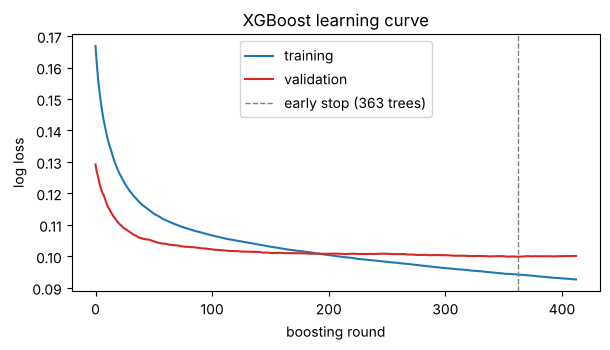

In [11]:
# ---- Training diagnostics: does the boosted model overfit? (log loss per boosting round, train vs validation) ---------
hist_xgb = xgb_model.evals_result()
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(hist_xgb["validation_0"]["logloss"], label="training", color="#1f77b4")
ax.plot(hist_xgb["validation_1"]["logloss"], label="validation", color="#d62728")
ax.axvline(xgb_model.best_iteration, ls="--", color="grey", lw=1, label=f"early stop ({xgb_model.best_iteration + 1} trees)")
ax.set_xlabel("boosting round"); ax.set_ylabel("log loss"); ax.set_title("XGBoost learning curve"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "01_learning_curve.png", dpi=150); plt.show()

---
# 4. MODEL VALIDATION
*(Component 4 of 5)*

The final model is applied **once** to the unseen test subset (January to July 2026 observation months), which was never used for fitting, early stopping, threshold selection or hyper-parameter choice. Metrics are chosen for a minority-class problem: accuracy is shown but not relied on.

In [12]:
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score)

def ece(y, p, bins=10):
    q = pd.qcut(p, bins, duplicates="drop"); g = pd.DataFrame({"y": y, "p": p, "q": q}).groupby("q", observed=True)
    return float((g.size() / len(y) * (g.y.mean() - g.p.mean()).abs()).sum())

def top_decile(y, p, frac=0.10):
    k = max(1, int(round(len(y) * frac))); idx = np.argsort(-p)[:k]
    return y[idx].sum() / max(y.sum(), 1), y[idx].mean() / y.mean()      # recall captured, lift

def evaluate(y, p, thr):
    yhat = (p >= thr).astype(int); rec10, lift10 = top_decile(y, p)
    return {"ROC_AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "F1": f1_score(y, yhat), "accuracy": accuracy_score(y, yhat),
            "top10%_recall": rec10, "top10%_lift": lift10, "base_rate": y.mean()}

scores = {  # probabilities / risk scores for every subset and model
    "XGBoost": {"train": xgb_model.predict_proba(Ttr)[:, 1], "valid": p_va_xgb, "test": xgb_model.predict_proba(Tte)[:, 1]},
    "Logistic regression": {"train": lr_model.predict_proba(Ltr)[:, 1], "valid": lr_model.predict_proba(Lva)[:, 1], "test": lr_model.predict_proba(Lte)[:, 1]},
}
thr = {"XGBoost": THRESH, "Logistic regression": THRESH_LR}
rows = {}
for m in scores:
    for s, y in [("train", ytr), ("valid", yva), ("test", yte)]:
        rows[(m, s)] = evaluate(y, scores[m][s], thr[m])
# rule baseline (no viewing in the last 30 days): binary flag, so threshold metrics + rank metrics on days-since-last-session
for s, df, y in [("train", train, ytr), ("valid", valid, yva), ("test", test, yte)]:
    sc = rule_score(df); rows[("Rule: no viewing 30d", s)] = evaluate(y, sc / sc.max(), RULE_THRESH / sc.max())
results = pd.DataFrame(rows).T
results.index.names = ["model", "subset"]
test_tbl = results.xs("test", level="subset")
test_tbl[["ROC_AUC", "PR_AUC", "log_loss", "Brier", "ECE", "precision", "recall", "F1", "top10%_recall", "top10%_lift"]].round(3)

,ROC_AUC,PR_AUC,log_loss,Brier,ECE,precision,recall,F1,top10%_recall,top10%_lift
model,,,,,,,,,,
XGBoost,0.752,0.210,0.138,0.032,0.012,0.354,0.204,0.258,0.381,3.807
Logistic regression,0.721,0.169,0.150,0.033,0.017,0.277,0.204,0.235,0.372,3.718
Rule: no viewing 30d,0.437,0.030,1.998,0.236,0.304,0.032,0.496,0.061,0.044,0.443


In [13]:
# ---- Uncertainty: bootstrap over SUBSCRIBERS (a fan's rows are correlated, so whole fans are resampled) ----------------
rng = np.random.default_rng(SEED)
groups = test.subscriber_id.to_numpy(); ug = pd.unique(groups)
by_fan = pd.Series(np.arange(len(test))).groupby(groups).apply(np.array).to_dict()
B = 500; boot = {m: {"PR_AUC": [], "ROC_AUC": []} for m in scores}; diff = []
for _ in range(B):
    idx = np.concatenate([by_fan[g] for g in rng.choice(ug, len(ug))])
    if yte[idx].sum() == 0: continue
    pa = {}
    for m in scores:
        pa[m] = average_precision_score(yte[idx], scores[m]["test"][idx])
        boot[m]["PR_AUC"].append(pa[m]); boot[m]["ROC_AUC"].append(roc_auc_score(yte[idx], scores[m]["test"][idx]))
    diff.append(pa["XGBoost"] - pa["Logistic regression"])
ci = lambda a: np.percentile(a, [2.5, 97.5])
for m in scores:
    print(f"{m:20s} test PR-AUC {results.loc[(m, 'test'), 'PR_AUC']:.3f}  95% CI [{ci(boot[m]['PR_AUC'])[0]:.3f}, {ci(boot[m]['PR_AUC'])[1]:.3f}]"
          f" | ROC-AUC {results.loc[(m, 'test'), 'ROC_AUC']:.3f}  95% CI [{ci(boot[m]['ROC_AUC'])[0]:.3f}, {ci(boot[m]['ROC_AUC'])[1]:.3f}]")
d = np.array(diff); print(f"\nXGBoost minus logistic regression, PR-AUC: mean {d.mean():+.3f}, 95% CI [{ci(d)[0]:+.3f}, {ci(d)[1]:+.3f}] "
                         f"-> {'XGBoost better' if ci(d)[0] > 0 else 'not clearly different from logistic regression' if ci(d)[1] > 0 else 'logistic regression better'}")

XGBoost              test PR-AUC 0.210  95% CI [0.141, 0.292] | ROC-AUC 0.752  95% CI [0.702, 0.800]
Logistic regression  test PR-AUC 0.169  95% CI [0.110, 0.240] | ROC-AUC 0.721  95% CI [0.675, 0.768]

XGBoost minus logistic regression, PR-AUC: mean +0.041, 95% CI [+0.007, +0.083] -> XGBoost better


In [14]:
# ---- Model validation summary: train vs validation vs unseen test (gap = overfitting check) -----------------------------------
summ = results.loc["XGBoost"][["ROC_AUC", "PR_AUC", "log_loss", "precision", "recall", "F1", "top10%_recall", "top10%_lift", "base_rate"]].round(3)
print("XGBoost (final model) by subset:"); display(summ) if "display" in globals() else print(summ)
cm = confusion_matrix(yte, (scores["XGBoost"]["test"] >= THRESH).astype(int))
tn, fp, fn, tp = cm.ravel()
print(f"\nTest confusion matrix at the validation-chosen threshold {THRESH:.3f}: TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")
print(f"Of every 100 subscribers flagged, {100 * tp / max(tp + fp, 1):.0f} really cancel in the next {HORIZON} days (base rate {yte.mean():.1%}).")
print(f"Sanity check on the SS1 'disengagement' assumption (test set, mean sessions in the last 30 days): churners {test.loc[test.y == 1, 'sessions_30d'].mean():.2f} vs stayers {test.loc[test.y == 0, 'sessions_30d'].mean():.2f}")
r, l = top_decile(yte, scores['XGBoost']['test']); print(f"Contacting only the top 10% riskiest subscriber-months reaches {r:.0%} of all churners ({l:.1f}x better than random).")
results.round(4).to_csv(OUT_DIR / "metrics_by_model_and_subset.csv")
json.dump({"horizon_days": HORIZON, "threshold": THRESH, "best_max_depth": int(best_depth), "trees": int(xgb_model.best_iteration + 1),
           "test_metrics": {k: float(v) for k, v in results.loc[("XGBoost", "test")].items()}}, open(OUT_DIR / "xgboost_summary.json", "w"), indent=2)

XGBoost (final model) by subset:
        ROC_AUC  PR_AUC  log_loss  precision  recall     F1  top10%_recall  top10%_lift  base_rate
subset                                                                                            
train     0.923   0.635     0.094      0.556   0.621  0.587          0.746        7.463      0.042
valid     0.806   0.311     0.100      0.489   0.322  0.388          0.545        5.452      0.028
test      0.752   0.210     0.138      0.354   0.204  0.258          0.381        3.807      0.036

Test confusion matrix at the validation-chosen threshold 0.183: TN=2,976 FP=42 FN=90 TP=23
Of every 100 subscribers flagged, 35 really cancel in the next 30 days (base rate 3.6%).
Sanity check on the SS1 'disengagement' assumption (test set, mean sessions in the last 30 days): churners 0.88 vs stayers 0.74
Contacting only the top 10% riskiest subscriber-months reaches 38% of all churners (3.8x better than random).


---
# 5. RESULTS VISUALISATION
*(Component 5 of 5)*

Graphs show both the **training** and the **unseen test** behaviour of the final model, so over-fitting is visible, and put the result next to the baselines.

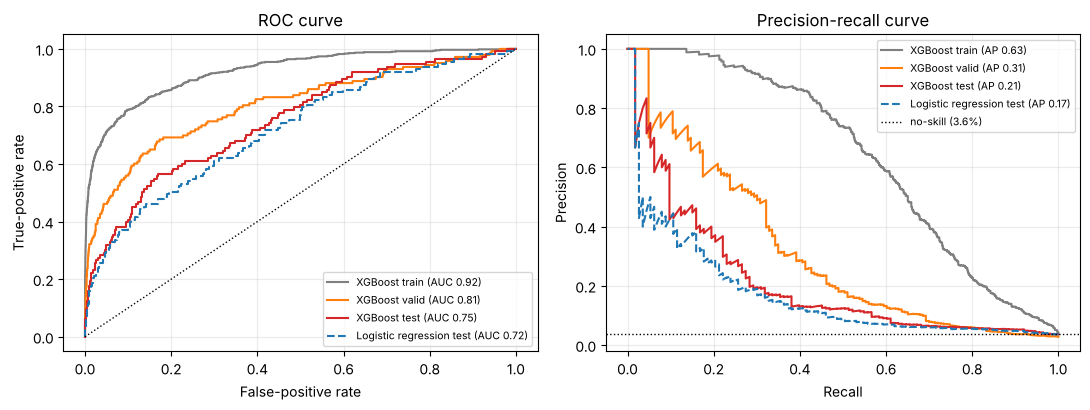

In [15]:
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
COL = {"train": "#7f7f7f", "valid": "#ff7f0e", "test": "#d62728", "XGBoost": "#d62728", "Logistic regression": "#1f77b4"}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for s, y in [("train", ytr), ("valid", yva), ("test", yte)]:
    f, t, _ = roc_curve(y, scores["XGBoost"][s]); ax[0].plot(f, t, color=COL[s], label=f"XGBoost {s} (AUC {roc_auc_score(y, scores['XGBoost'][s]):.2f})")
    pr, rc, _ = precision_recall_curve(y, scores["XGBoost"][s]); ax[1].plot(rc, pr, color=COL[s], label=f"XGBoost {s} (AP {average_precision_score(y, scores['XGBoost'][s]):.2f})")
f, t, _ = roc_curve(yte, scores["Logistic regression"]["test"]); ax[0].plot(f, t, "--", color=COL["Logistic regression"], label=f"Logistic regression test (AUC {roc_auc_score(yte, scores['Logistic regression']['test']):.2f})")
pr, rc, _ = precision_recall_curve(yte, scores["Logistic regression"]["test"]); ax[1].plot(rc, pr, "--", color=COL["Logistic regression"], label=f"Logistic regression test (AP {average_precision_score(yte, scores['Logistic regression']['test']):.2f})")
ax[0].plot([0, 1], [0, 1], ":", color="k", lw=1); ax[1].axhline(yte.mean(), ls=":", color="k", lw=1, label=f"no-skill ({yte.mean():.1%})")
ax[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curve"); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
for a in ax: a.legend(fontsize=7.5, loc="best"); a.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "02_roc_pr_curves.png", dpi=150); plt.show()

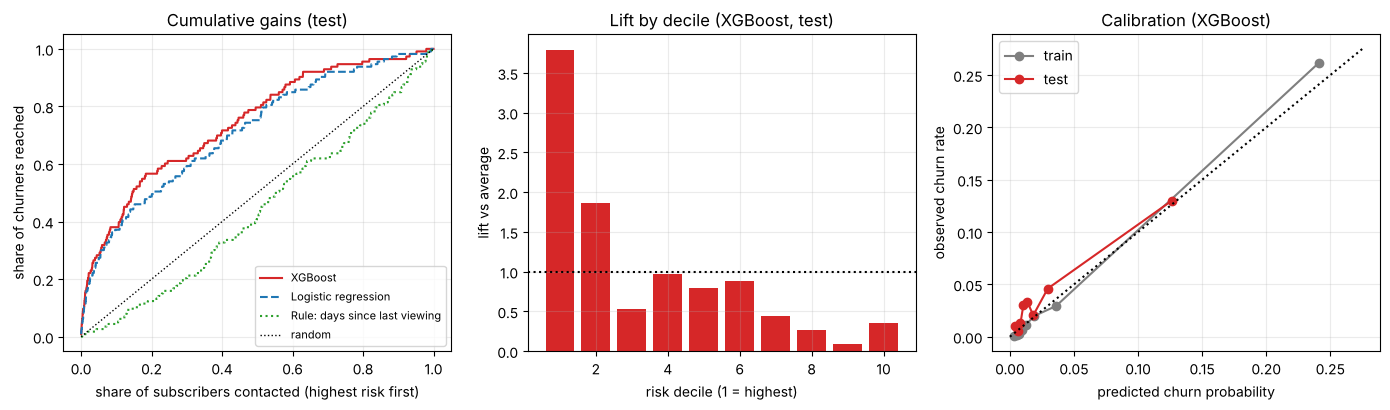

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
# (a) cumulative gains / lift on the unseen test set
for m, ls in [("XGBoost", "-"), ("Logistic regression", "--")]:
    order = np.argsort(-scores[m]["test"]); gain = np.cumsum(yte[order]) / yte.sum(); x = np.arange(1, len(yte) + 1) / len(yte)
    ax[0].plot(x, gain, ls, color=COL[m], label=m)
order = np.argsort(-rule_score(test)); ax[0].plot(np.arange(1, len(yte) + 1) / len(yte), np.cumsum(yte[order]) / yte.sum(), ":", color="#2ca02c", label="Rule: days since last viewing")
ax[0].plot([0, 1], [0, 1], ":", color="k", lw=1, label="random"); ax[0].set(xlabel="share of subscribers contacted (highest risk first)", ylabel="share of churners reached", title="Cumulative gains (test)"); ax[0].legend(fontsize=8)
# (b) lift per decile
dec = pd.DataFrame({"y": yte, "p": scores["XGBoost"]["test"]}); dec["decile"] = pd.qcut(dec.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = dec.groupby("decile", observed=True).y.mean() / yte.mean()
ax[1].bar(lift.index.astype(int), lift.values, color="#d62728"); ax[1].axhline(1, ls=":", color="k"); ax[1].set(xlabel="risk decile (1 = highest)", ylabel="lift vs average", title="Lift by decile (XGBoost, test)")
# (c) calibration
for s, y in [("train", ytr), ("test", yte)]:
    fr, mp = calibration_curve(y, scores["XGBoost"][s], n_bins=8, strategy="quantile"); ax[2].plot(mp, fr, "o-", color=COL[s], label=s)
mx = max(ax[2].get_xlim()[1], ax[2].get_ylim()[1]); ax[2].plot([0, mx], [0, mx], ":", color="k"); ax[2].set(xlabel="predicted churn probability", ylabel="observed churn rate", title="Calibration (XGBoost)"); ax[2].legend()
for a in ax: a.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "03_gains_lift_calibration.png", dpi=150); plt.show()

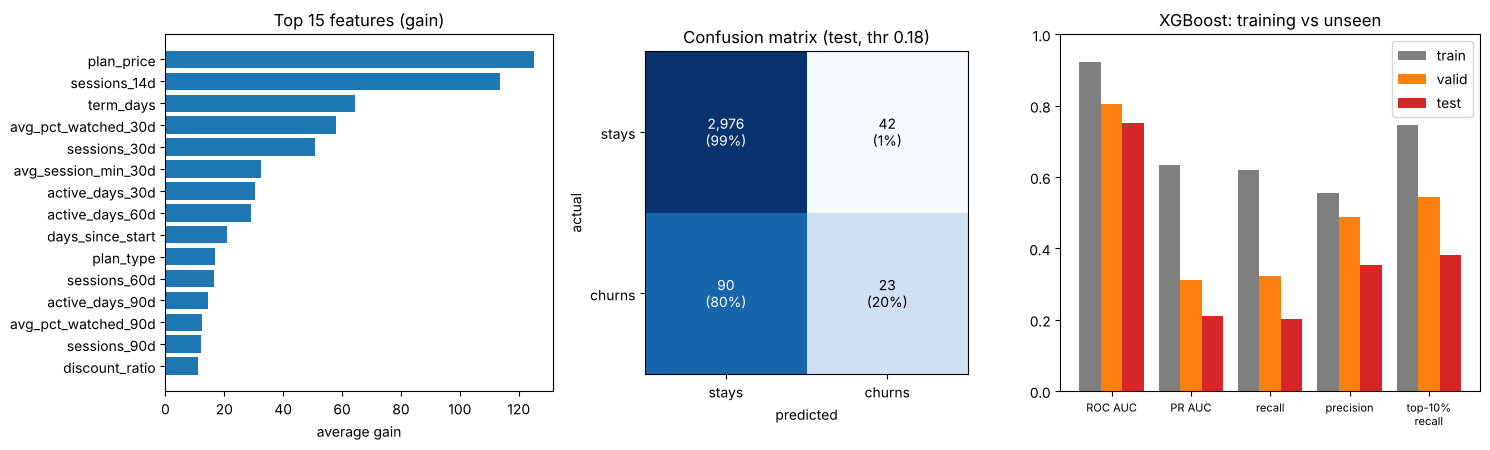

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1.3]})
# (a) feature importance (gain) - which behaviours signal churn
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")); imp.index = [X_cols[int(k[1:])] for k in imp.index]
imp = imp.sort_values().tail(15); ax[0].barh(imp.index, imp.values, color="#1f77b4"); ax[0].set(title="Top 15 features (gain)", xlabel="average gain")
# (b) confusion matrix on the unseen test set
cmn = cm / cm.sum(axis=1, keepdims=True)
ax[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, f"{v:,}\n({cmn[i, j]:.0%})", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black")
ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["stays", "churns"], yticklabels=["stays", "churns"], xlabel="predicted", ylabel="actual", title=f"Confusion matrix (test, thr {THRESH:.2f})")
# (c) metric comparison: train vs validation vs test
met = ["ROC_AUC", "PR_AUC", "recall", "precision", "top10%_recall"]; w = 0.27
for i, s in enumerate(["train", "valid", "test"]):
    vals = [results.loc[("XGBoost", s), k] for k in met]; ax[2].bar(np.arange(len(met)) + (i - 1) * w, vals, w, label=s, color=COL[s])
ax[2].set_xticks(range(len(met))); ax[2].set_xticklabels(["ROC AUC", "PR AUC", "recall", "precision", "top-10%\nrecall"], fontsize=8); ax[2].set_ylim(0, 1); ax[2].legend(); ax[2].set_title("XGBoost: training vs unseen")
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "04_importance_confusion_metrics.png", dpi=150); plt.show()

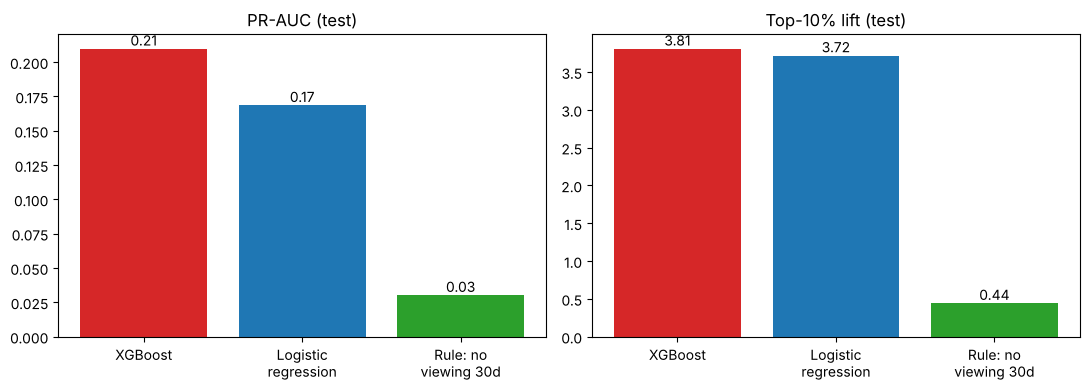

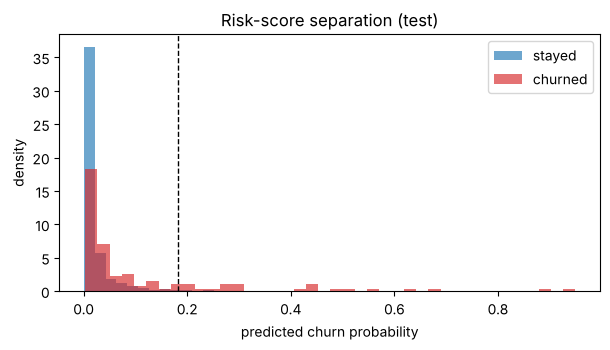

Saved figures, metrics and ranked predictions to /tmp/claude-0/w/fin/outputs


In [18]:
# Model comparison on the unseen test set and risk-score separation
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
names = ["XGBoost", "Logistic regression", "Rule: no viewing 30d"]; cols = ["#d62728", "#1f77b4", "#2ca02c"]
for k, (metric, ttl) in enumerate([("PR_AUC", "PR-AUC (test)"), ("top10%_lift", "Top-10% lift (test)")]):
    vals = [results.loc[(n, "test"), metric] for n in names]; ax[k].bar(range(3), vals, color=cols)
    for i, v in enumerate(vals): ax[k].text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax[k].set_xticks(range(3)); ax[k].set_xticklabels(["XGBoost", "Logistic\nregression", "Rule: no\nviewing 30d"]); ax[k].set_title(ttl)
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "05_model_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.hist(scores["XGBoost"]["test"][yte == 0], bins=40, alpha=.65, label="stayed", color="#1f77b4", density=True)
ax.hist(scores["XGBoost"]["test"][yte == 1], bins=40, alpha=.65, label="churned", color="#d62728", density=True)
ax.axvline(THRESH, ls="--", color="k", lw=1); ax.set(xlabel="predicted churn probability", ylabel="density", title="Risk-score separation (test)"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "figures" / "06_score_distribution.png", dpi=150); plt.show()

# Persist predictions so the client can inspect the ranked risk list
out = test[["subscriber_id", "subscription_id", "obs_date", "y"]].assign(churn_risk=scores["XGBoost"]["test"]).sort_values("churn_risk", ascending=False)
out.to_csv(OUT_DIR / "test_predictions_ranked.csv", index=False); print("Saved figures, metrics and ranked predictions to", OUT_DIR.resolve())